In [77]:
from datetime import datetime, timedelta
import os
from dotenv import load_dotenv
import requests
import pandas as pd

import seaborn as sns
import missingno as msno
import matplotlib.pyplot as plt

In [78]:
# Charger les variables du fichier .env
load_dotenv()

True

In [79]:
API_KEY = os.getenv("OPENAGENDA_API_KEY")
if not API_KEY:
    raise ValueError(
        "La clé API OpenAgenda n'est pas définie dans l'environnement."
    )

In [80]:
BASE_URL = "https://api.openagenda.com/v2"

# La clé API est placée uniquement dans les en-têtes HTTP (jamais dans l'URL)
headers = {"Accept": "application/json", "key": API_KEY}

In [81]:
# Rechercher les agendas basés à Paris
agendas_url = f"{BASE_URL}/agendas"
params = {"search": "Paris"} 

In [82]:
response = requests.get(agendas_url, headers=headers, params=params)

if response.status_code != 200:
    print(f"Erreur lors de la récupération des agendas : {response.status_code}")
    exit()

In [83]:
agendas = response.json().get("agendas", [])

In [84]:
df_ag = pd.json_normalize(agendas)
print(df_ag.columns)

Index(['uid', 'image', 'description', 'official', 'title', 'slug'], dtype='str')


In [85]:
print (agendas)

[{'uid': 76783418, 'image': 'https://img.openagenda.com/main/b16e9a8856d84e44bfac04dc4d1e1067.300x0.image.jpg', 'description': 'Les événements de la cathédrale Notre-Dame de Paris.', 'official': True, 'title': 'Notre-Dame de Paris', 'slug': 'notre-dame-de-paris'}, {'uid': 82290100, 'image': 'https://img.openagenda.com/main/70391fc1c7734d13862db872685cf056.300x0.image.jpg', 'description': "Sélection d'événements diocésains et paroissiaux des églises de Paris.", 'official': True, 'title': 'Diocèse de Paris', 'slug': 'dioceseparis'}, {'uid': 3541840, 'image': 'https://img.openagenda.com/main/2ffd35df45a94506811b39f2f50be54c.300x0.image.jpg', 'description': "La Maison de l’Europe de Paris est une association régie par la loi de 1901 créée en 1956 et reconnue d’utilité publique par décret en 1973. Elle accueille un Centre Europe Direct, Europe Direct Paris, depuis 2008 grâce au soutien de la Commission européenne. Ensemble, leur mission est de rapprocher les citoyens de l'Union européenne."

In [86]:
# Définition de la période (sur +/- - 6 mois )
now = datetime.now()- timedelta(days=128)
one_year_later = now + timedelta(days=128)

In [87]:
# Parcourir les agendas pour récupérer les événements
all_events = []
for agenda in agendas:
    agenda_uid = agenda["uid"]
    events_url = f"{BASE_URL}/agendas/{agenda_uid}/events"

    event_params = {
        "timings[gte]": now.strftime("%Y-%m-%dT%H:%M:%SZ"),
        "timings[lte]": one_year_later.strftime("%Y-%m-%dT%H:%M:%SZ"),
    }  # Toujours sans clé dans l'URL

    events_res = requests.get(events_url, headers=headers, params=event_params)
    if events_res.status_code == 200:
        events = events_res.json().get("events", [])
        all_events.extend(events)

print(
    f"Nombre total d'événements trouvés sur Paris via l'API v2 : {len(all_events)}"
)

Nombre total d'événements trouvés sur Paris via l'API v2 : 229


In [88]:
# Aplatissement des données imbriquées
df = pd.json_normalize(all_events)

In [89]:
df.head()


,featured,attendanceMode,canonicalUrl,timezone,imageCredits,evenements-lies-au-calendrier,onlineAccessLink,uid,types-devenement,categories,slug,status,image.filename,image.size.width,image.size.height,image.variants,image.base,dateRange.ar,dateRange.de,dateRange.en,dateRange.it,dateRange.fr,dateRange.es,dateRange.nl,originAgenda.uid,originAgenda.image,originAgenda.title,description.fr,title.fr,lastTiming.end,lastTiming.id,lastTiming.begin,rights.license.name,rights.license.id,rights.license.url,rights.licensor.agendaUid,rights.licensor.name,rights.licensor.url,rights.publisher.agendaUid,rights.publisher.name,rights.publisher.url,firstTiming.end,firstTiming.id,firstTiming.begin,location.address,location.city,location.latitude,location.name,location.longitude,nextTiming.end,nextTiming.id,nextTiming.begin,organisateur,thematique,evenement-europe,particularite,portee-de-levenement,type-de-public,actions,nextTiming,keywords.fr,public,type-devenement,gestion-admin-ne-pas-remplir,keywords.en,description.en,title.en,thematiques-info-jeunes,type-de-public-vise,diffusion-sur-le-site-info-jeunes-france,tags,votre-recherchez,description.de,description.it,description.es,title.de,title.it,title.es,categorie-devenement,festival
0,False,1,https://openagenda.com/openagenda-saint_eustac...,Europe/Paris,NaN,[],NaN,39411970,[5],[19],lumiere-divine-installation-de-jiang-qiong-er,1,333a754ca4f043acab6fb0f4b3b4f6fb.base.image.jpg,700.0,990.0,[{'filename': '333a754ca4f043acab6fb0f4b3b4f6f...,https://img.openagenda.com/main/,١٣ أكتوبر ٢٠٢٦ - ١ أبريل ٢٠٢٧,13 Oktober 2026 - 1 April 2027,13 October 2026 - 1 April 2027,13 ottobre 2026 - 1 aprile 2027,13 octobre 2026 - 1 avril 2027,13 octubre 2026 - 1 abril 2027,13 oktober 2026 - 1 april 2027,70296720,1463997eaca64c1aae0b2c352378407e.full.image.jpg,Saint-Eustache,jusqu'au printemps 2027,"Lumière divine, installation de Jiang Qiong er",2027-04-01T18:30:00.000+02:00,QTG7NP,2027-04-01T08:30:00.000+02:00,Licence Ouverte 2.0,etalab-2.0,https://www.data.gouv.fr/pages/legal/licences/...,70296720,Saint-Eustache,https://www.saint-eustache.org/,82290100,Diocèse de Paris,https://dioceseparis.fr,2026-10-13T18:30:00.000+02:00,Y35FJ7,2026-10-13T08:30:00.000+02:00,"146 rue Rambuteau, 75001 Paris",Paris,48.863197,Église Saint-Eustache,2.345667,2026-10-15T18:30:00+02:00,9SFSXH,2026-10-15T08:30:00+02:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,False,1,https://openagenda.com/saint-jean-baptiste-de-...,Europe/Paris,NaN,[],NaN,13510268,[12],[],scrabble-et-compagnie-5762694,1,3264a5bb466b4175a57ea876208a775a.base.image.jpg,700.0,359.0,[{'filename': '3264a5bb466b4175a57ea876208a775...,https://img.openagenda.com/main/,٢٥ يونيو ٢٠٢٦ - ١ يوليو ٢٠٢٧undefined,"25 Juni 2026 - 1 Juli 2027, jeden Donnerstag","25 June 2026 - 1 July 2027, every Thursday","25 giugno 2026 - 1 luglio 2027, ogni giovedì","25 juin 2026 - 1 juillet 2027, les jeudis","25 junio 2026 - 1 julio 2027, todos los jueves","25 juni 2026 - 1 juli 2027, alle donderdagen",70373762,4a2a0fb337f849d1b1e727fb82b53a12.full.image.jpg,Saint-Jean-Baptiste de La Salle,"Tous les jeudis, de 14h30 à 17h00 (Pendant tou...",SCRABBLE ET COMPAGNIE,2027-07-01T17:00:00.000+02:00,NaN,2027-07-01T14:30:00.000+02:00,Licence Ouverte 2.0,etalab-2.0,https://www.data.gouv.fr/pages/legal/licences/...,70373762,Saint-Jean-Baptiste de La Salle,https://openagenda.com/saint-jean-baptiste-de-...,82290100,Diocèse de Paris,https://dioceseparis.fr,2026-06-25T17:00:00.000+02:00,NaN,2026-06-25T14:30:00.000+02:00,70 rue falguiere 75015,Paris,48.840519,Salle Don Bosco - SJBS,2.312848,2026-10-15T17:00:00+02:00,NaN,2026-10-15T14:30:00+02:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,False,1,https://openagenda.com/openagenda-saint_eustac...,Europe/Paris,LeJoliStudio,[],NaN,78139916,[4],[19],visites-guidees-en-anglais-de-leglise-saint-eu...,1,a01ae86e7d6841339954a9f5d7c7ca09

In [90]:
print(df.columns)

Index(['featured', 'attendanceMode', 'canonicalUrl', 'timezone',
       'imageCredits', 'evenements-lies-au-calendrier', 'onlineAccessLink',
       'uid', 'types-devenement', 'categories', 'slug', 'status',
       'image.filename', 'image.size.width', 'image.size.height',
       'image.variants', 'image.base', 'dateRange.ar', 'dateRange.de',
       'dateRange.en', 'dateRange.it', 'dateRange.fr', 'dateRange.es',
       'dateRange.nl', 'originAgenda.uid', 'originAgenda.image',
       'originAgenda.title', 'description.fr', 'title.fr', 'lastTiming.end',
       'lastTiming.id', 'lastTiming.begin', 'rights.license.name',
       'rights.license.id', 'rights.license.url', 'rights.licensor.agendaUid',
       'rights.licensor.name', 'rights.licensor.url',
       'rights.publisher.agendaUid', 'rights.publisher.name',
       'rights.publisher.url', 'firstTiming.end', 'firstTiming.id',
       'firstTiming.begin', 'location.address', 'location.city',
       'location.latitude', 'location.name', 'lo

# Visualisation des données du data frame

<Axes: >

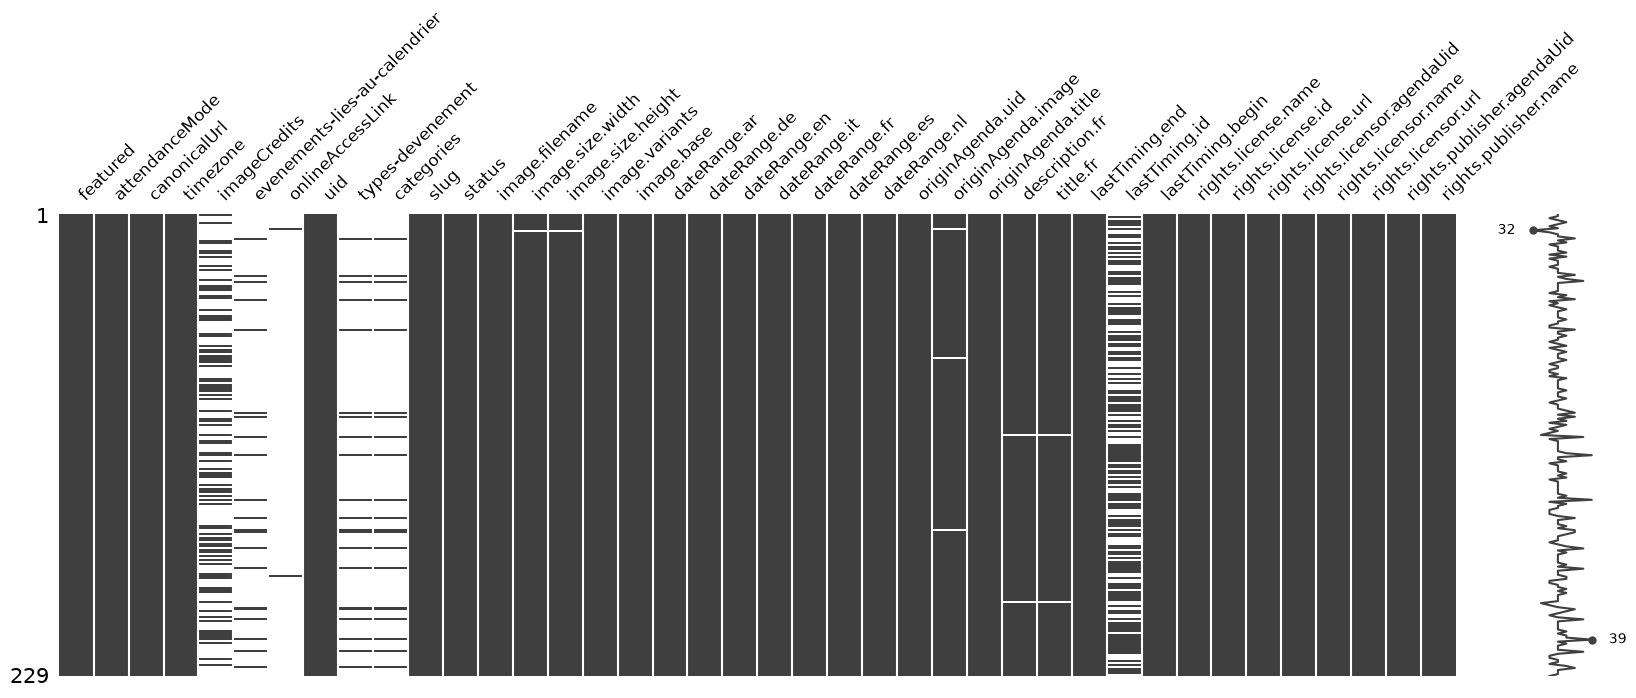

In [91]:
nb_lignes = df.shape[0]
colonne1 =[
    'featured', 'attendanceMode', 'canonicalUrl', 'timezone',
       'imageCredits', 'evenements-lies-au-calendrier', 'onlineAccessLink',
       'uid', 'types-devenement', 'categories', 'slug', 'status',
       'image.filename', 'image.size.width', 'image.size.height',
       'image.variants', 'image.base', 'dateRange.ar', 'dateRange.de',
       'dateRange.en', 'dateRange.it', 'dateRange.fr', 'dateRange.es',
       'dateRange.nl', 'originAgenda.uid', 'originAgenda.image',
       'originAgenda.title', 'description.fr', 'title.fr', 'lastTiming.end',
       'lastTiming.id', 'lastTiming.begin', 'rights.license.name',
       'rights.license.id', 'rights.license.url', 'rights.licensor.agendaUid',
       'rights.licensor.name', 'rights.licensor.url',
       'rights.publisher.agendaUid', 'rights.publisher.name'
]

msno.matrix(df[colonne1].sample(nb_lignes) ,figsize=(20,6) , fontsize=12)


<Axes: >

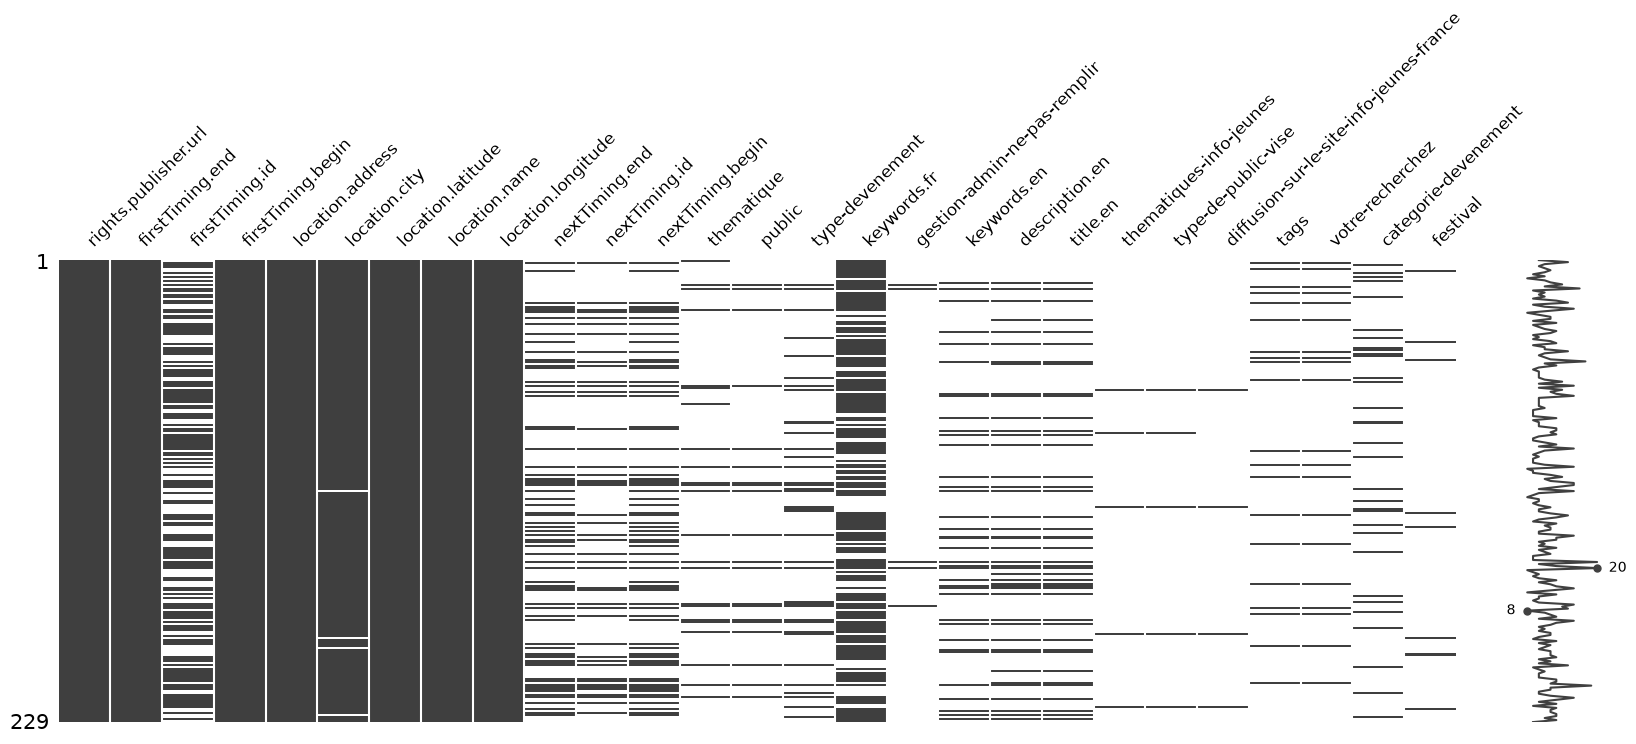

In [92]:
colonne2 =[
    'rights.publisher.url', 'firstTiming.end', 'firstTiming.id',
       'firstTiming.begin', 'location.address', 'location.city',
       'location.latitude', 'location.name', 'location.longitude',
       'nextTiming.end', 'nextTiming.id', 'nextTiming.begin', 'thematique',
       'public', 'type-devenement', 'keywords.fr',
       'gestion-admin-ne-pas-remplir', 'keywords.en', 'description.en',
       'title.en', 'thematiques-info-jeunes', 'type-de-public-vise',
       'diffusion-sur-le-site-info-jeunes-france', 'tags', 'votre-recherchez',
       'categorie-devenement', 'festival'
]

msno.matrix(df[colonne2].sample(nb_lignes) ,figsize=(20,6) , fontsize=12)

# Gestion des colonnes utiles pour notre POC

In [93]:
colonnes_utiles = [
    'uid', 
    'title.fr', 
    'description.fr', 
    'location.name', 
    'location.city', 
    'location.address', 
    'firstTiming.begin', 
    'firstTiming.end',
    'canonicalUrl'
]

df_filtre = df[colonnes_utiles].copy()

# Renommer pour plus de simplicité si besoin
df_filtre.columns = ['id', 'titre', 'description', 'lieu', 'ville', 'adresse', 'debut','fin', 'url']

df_filtre.head()

,id,titre,description,lieu,ville,adresse,debut,fin,url
0,39411970,"Lumière divine, installation de Jiang Qiong er",jusqu'au printemps 2027,Église Saint-Eustache,Paris,"146 rue Rambuteau, 75001 Paris",2026-10-13T08:30:00.000+02:00,2026-10-13T18:30:00.000+02:00,https://openagenda.com/openagenda-saint_eustac...
1,13510268,SCRABBLE ET COMPAGNIE,"Tous les jeudis, de 14h30 à 17h00 (Pendant tou...",Salle Don Bosco - SJBS,Paris,70 rue falguiere 75015,2026-06-25T14:30:00.000+02:00,2026-06-25T17:00:00.000+02:00,https://openagenda.com/saint-jean-baptiste-de-...
2,78139916,Visites guidées en anglais de l'église Saint-E...,Visites guidées en anglais de l'église Saint-E...,Église Saint-Eustache,Paris,"146 rue Rambuteau, 75001 Paris",2026-10-07T10:00:00.000+02:00,2026-10-07T11:00:00.000+02:00,https://openagenda.com/openagenda-saint_eustac...
3,11591535,Adoration eucharistique,chaque jeudi de 17h à 18h45,Église Saint-Pierre de Chaillot,Paris,"31 avenue Marceau, 75116 Paris",2026-02-19T17:00:00.000+01:00,2026-02-19T18:45:00.000+01:00,https://openagenda.com/saint-pierre-de-chaillo...
4,54688085,« Le jeudi j'adore »,Temps privilégié pour adorer le Saint-Sacrement,Eglise 70 rue falguière,Paris,70 rue Falguière,2026-09-24T17:30:00.000+02:00,2026-09-24T18:30:00.000+02:00,https://openagenda.com/saint-jean-baptiste-de-...


In [100]:
colonnes_utiles_completes = [
    'uid', 
    'title.fr', 
    'description.fr', 
    'dateRange.fr',          # Date lisible en français
    'firstTiming.begin',     # Date/heure de début (pour les tris)
    'firstTiming.end',       # Date/heure de fin
    'location.name',         # Nom du lieu
    'location.address',      # Adresse complète
    'location.city',         # Ville
    'location.latitude',     # Latitude (carte)
    'location.longitude',    # Longitude (carte)
    'canonicalUrl'           # Lien vers la page de l'événement
]

df_selection = df[colonnes_utiles_completes].copy()
# Renommer pour plus de simplicité si besoin
df_selection.columns = ['id', 'titre', 'description','date' ,'heure debut', 'heure fin','lieu', 'adresse', 'ville', 'latitude','longitude','url']

In [101]:
pd.set_option('display.max_columns',None)
df_selection.head()

,id,titre,description,date,heure debut,heure fin,lieu,adresse,ville,latitude,longitude,url
0,39411970,"Lumière divine, installation de Jiang Qiong er",jusqu'au printemps 2027,13 octobre 2026 - 1 avril 2027,2026-10-13T08:30:00.000+02:00,2026-10-13T18:30:00.000+02:00,Église Saint-Eustache,"146 rue Rambuteau, 75001 Paris",Paris,48.863197,2.345667,https://openagenda.com/openagenda-saint_eustac...
1,13510268,SCRABBLE ET COMPAGNIE,"Tous les jeudis, de 14h30 à 17h00 (Pendant tou...","25 juin 2026 - 1 juillet 2027, les jeudis",2026-06-25T14:30:00.000+02:00,2026-06-25T17:00:00.000+02:00,Salle Don Bosco - SJBS,70 rue falguiere 75015,Paris,48.840519,2.312848,https://openagenda.com/saint-jean-baptiste-de-...
2,78139916,Visites guidées en anglais de l'église Saint-E...,Visites guidées en anglais de l'église Saint-E...,7 - 31 octobre,2026-10-07T10:00:00.000+02:00,2026-10-07T11:00:00.000+02:00,Église Saint-Eustache,"146 rue Rambuteau, 75001 Paris",Paris,48.863197,2.345667,https://openagenda.com/openagenda-saint_eustac...
3,11591535,Adoration eucharistique,chaque jeudi de 17h à 18h45,"19 février 2026 - 15 juillet 2027, certains je...",2026-02-19T17:00:00.000+01:00,2026-02-19T18:45:00.000+01:00,Église Saint-Pierre de Chaillot,"31 avenue Marceau, 75116 Paris",Paris,48.865263,2.299851,https://openagenda.com/saint-pierre-de-chaillo...
4,54688085,« Le jeudi j'adore »,Temps privilégié pour adorer le Saint-Sacrement,"24 septembre 2026 - 1 juillet 2027, certains j...",2026-09-24T17:30:00.000+02:00,2026-09-24T18:30:00.000+02:00,Eglise 70 rue falguière,70 rue Falguière,Paris,48.840519,2.312848,https://openagenda.com/saint-jean-baptiste-de-...


# Clean df_selection et  texte

In [105]:

# Combiner les colonnes en un texte descriptif  pour chaque événement
df_clean['texte_a_vectoriser'] = (
    "Événement : " + df_clean['titre'] + ". " +
    "Description : " + df_clean['description'] + " " +
    "Lieu : " + df_clean['lieu'] + " (" + df_clean['adresse'] + ", " + df_clean['ville'] + "). " +
    "Période : " + df_clean['date']
)

<Axes: >

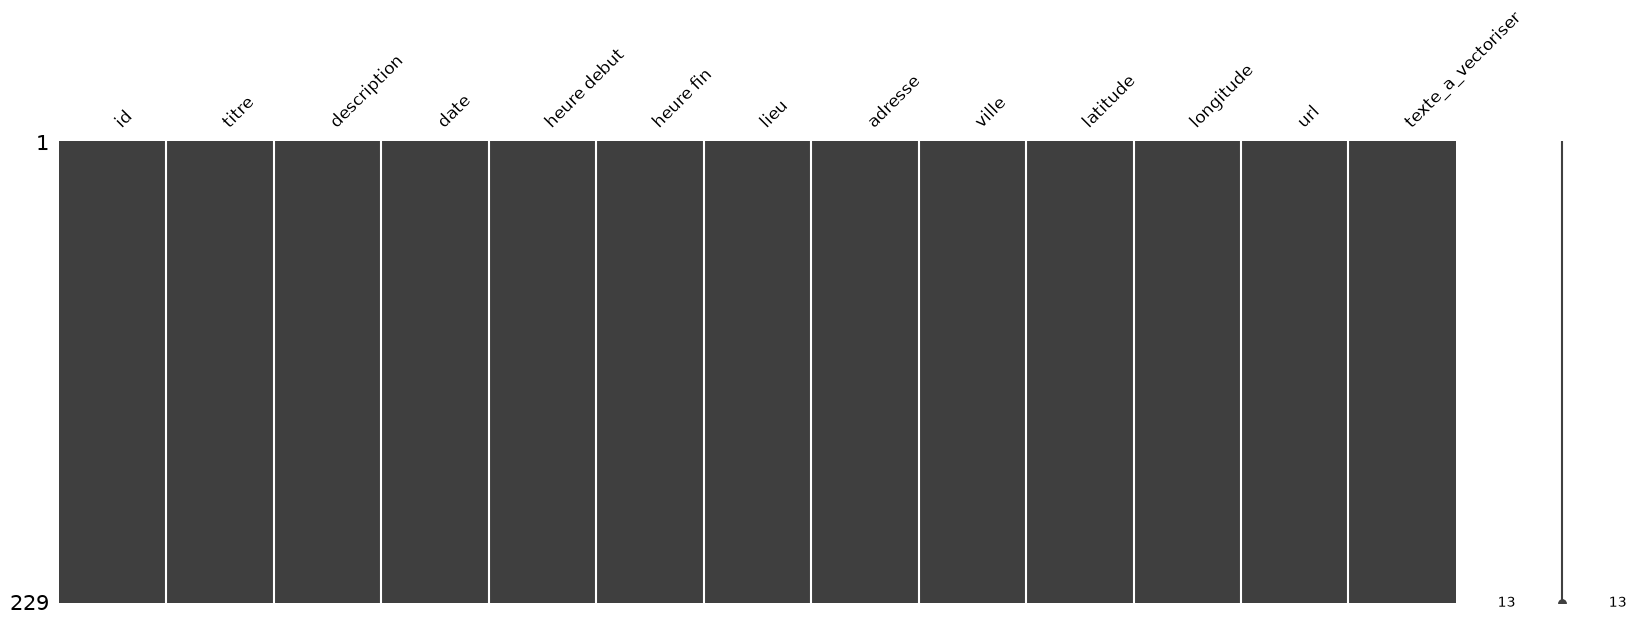

In [108]:
# Remplace NaN par chaines vides
df_clean = df_selection.fillna("")
msno.matrix(df_clean.sample(nb_lignes) ,figsize=(20,6) , fontsize=12)

# enregistrement des data 

In [107]:
df_clean.to_csv("./data/evenement.csv", index = False , encoding ="utf-8")